Active Sources: 2, Total Spend: $69.79 / $70.00
Covered Points: 10 / 30 (Weighted Score: 69.0)


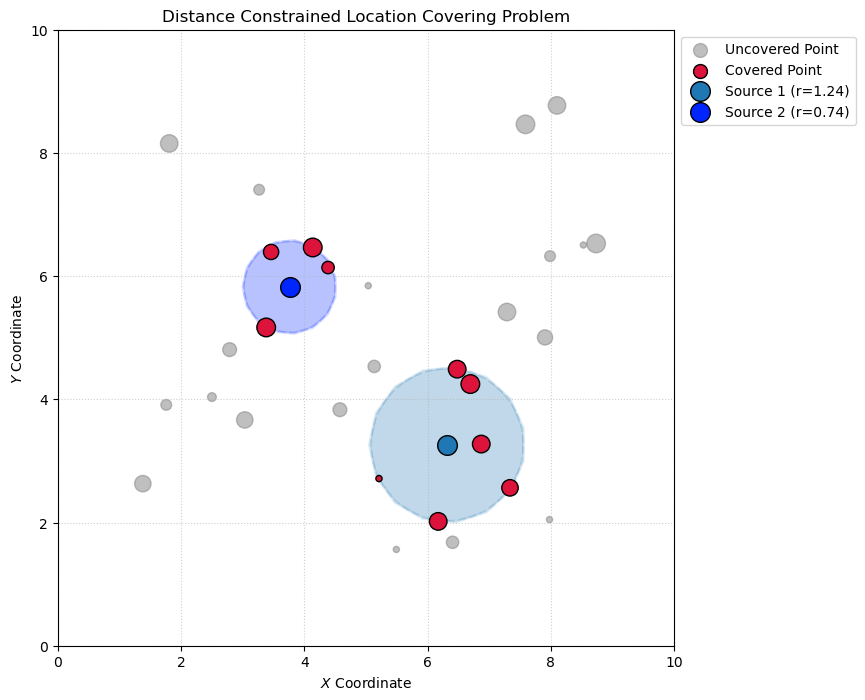

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pyomo.environ as pyo


k = 30 # Demand points
s = 4 # Number of potential source locations
budget = 70 # Total budget to cover points
c_fixed = 25 # Fixed start-up cost
c_var = 10 # Variable cost associated with distance 
max_distance = 1.5 # maximum distance per source
number_of_cuts = 15 
BigM = 15  

points = {i: (np.random.uniform(1, 9), np.random.uniform(1, 9)) for i in range(k)}
weights = {i: float(np.random.randint(1, 10)) for i in range(k)}
angles = [2 * np.pi * m / number_of_cuts for m in range(number_of_cuts)]


def obj_rule(model):
    return sum(weights[i] * model.y[i] for i in model.I)

def budget_rule(model): 
    return (sum(c_fixed * model.u[j] + c_var * model.r[j] for j in model.J)<= budget)

def distance_rule(model, i, j, m):
    """ Facility Location j; Demand Location i; Approximate Curve m"""
    px, py = points[i]
    theta = angles[m]
    return (model.x1[j] - px) * np.cos(theta) + (model.x2[j] - py) * np.sin(theta) <= model.r[j] + BigM * (1 - model.z[i, j])

def radius_activation_rule(model, j):
    return model.r[j] <= max_distance * model.u[j]


def x1_activation_rule(model, j):
    return model.x1[j] <= 10 * model.u[j]


def x2_activation_rule(model, j):
    return model.x2[j] <= 10 * model.u[j]


def coverage_activation_rule(model, i, j):
    return model.z[i, j] <= model.u[j]


def coverage_link_rule(model, i):
    return sum(model.z[i, j] for j in model.J) >= model.y[i]



model = pyo.ConcreteModel(name="MaxCoverage_Linearized")
model.I = pyo.Set(initialize=range(k))
model.J = pyo.Set(initialize=range(s))
model.M = pyo.Set(initialize=range(number_of_cuts))

model.x1 = pyo.Var(model.J, domain=pyo.Reals, bounds=(0, 10))
model.x2 = pyo.Var(model.J, domain=pyo.Reals, bounds=(0, 10))
model.r = pyo.Var(model.J, domain=pyo.NonNegativeReals, bounds=(0, max_distance))
model.u = pyo.Var(model.J, domain=pyo.Binary)
model.y = pyo.Var(model.I, domain=pyo.Binary)
model.z = pyo.Var(model.I, model.J, domain=pyo.Binary)

model.obj = pyo.Objective(rule=obj_rule, sense=pyo.maximize)
model.dist_con = pyo.Constraint(model.I, model.J, model.M, rule=distance_rule)
model.rad_act_con = pyo.Constraint(model.J, rule=radius_activation_rule)
model.budget_con = pyo.Constraint(rule=budget_rule)
model.cover_link_con = pyo.Constraint(model.I, rule=coverage_link_rule)
model.x1_act = pyo.Constraint(model.J, rule=x1_activation_rule)
model.x2_act = pyo.Constraint(model.J, rule=x2_activation_rule)

solver = pyo.SolverFactory('appsi_highs')
results = solver.solve(model)

active_sources = [j for j in model.J if pyo.value(model.u[j]) > 0.5]
covered_indices = [i for i in model.I if pyo.value(model.y[i]) > 0.5]
uncovered_indices = [i for i in model.I if pyo.value(model.y[i]) <= 0.5]
total_cost = sum(c_fixed * pyo.value(model.u[j]) + c_var * pyo.value(model.r[j])for j in model.J)

print(f"Active Sources: {len(active_sources)}, Total Spend: ${total_cost:.2f} / ${budget:.2f}")
print(f"Covered Points: {len(covered_indices)} / {k} (Weighted Score: {pyo.value(model.obj):.1f})")



fig, ax = plt.subplots(figsize=(8, 8))

# Uncovered points
uncovered_pts = np.array([points[i] for i in uncovered_indices])
if len(uncovered_pts) > 0:
    ax.scatter(
        uncovered_pts[:, 0], uncovered_pts[:, 1],
        c="gray",s=[weights[i] * 20 for i in uncovered_indices],
        alpha=0.5,label="Uncovered Point",
    )

# Covered points
covered_pts = np.array([points[i] for i in covered_indices])
if len(covered_pts) > 0:
    ax.scatter(
        covered_pts[:, 0],covered_pts[:, 1],
        c="crimson",s=[weights[i] * 20 for i in covered_indices],
        edgecolors="black",zorder=3,label="Covered Point",
    )

# Plot facilites
colors = ["#1f77b4", "#0026ff", "#0065e0", "#008486"]
for idx, j in enumerate(active_sources):
    xj1 = pyo.value(model.x1[j])
    xj2 = pyo.value(model.x2[j])
    rj = pyo.value(model.r[j])
    col = colors[idx % len(colors)]
    ax.scatter(xj1,xj2,c=col,s=200,edgecolors='black',zorder=5,label=f"Source {j+1} (r={rj:.2f})")
    circle = plt.Circle((xj1, xj2),rj,color=col,fill=True,alpha=0.15,linestyle="--",linewidth=1.5,)
    ax.add_patch(circle)


    vertex_angles = np.array(angles) + (np.pi / number_of_cuts)
    r_vertex = rj / np.cos(np.pi / number_of_cuts)

    poly_x = xj1 + r_vertex * np.cos(vertex_angles)
    poly_y = xj2 + r_vertex * np.sin(vertex_angles)
    ax.fill(
        poly_x,
        poly_y,
        color=col,
        alpha=0.15,
        linewidth=2,
        edgecolor=col,
        linestyle="-",
    )

# Formatting
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_aspect("equal")
ax.grid(True, linestyle=":", alpha=0.6)
ax.set_xlabel("$X$ Coordinate")
ax.set_ylabel("$Y$ Coordinate")
ax.set_title("Distance Constrained Location Covering Problem")
ax.legend(bbox_to_anchor=(1,1))
plt.show()

$ Min \displaystyle\sum_{(i,j) \in A} u_{ij}\theta_{ij}$

$ s.t. \ \alpha_i - \alpha_j + \theta_{ij} \geq 0 \ \forall \ (i,j) \in A$

$ \alpha_t - \alpha_s \geq 1$

$ \alpha_i \in \{0,1\} \ \forall \ i \in N$

$\theta_{ij} \in  \{0,1\} \ \forall \ (i,j) \in A$

